# Overview

Variable elimination is an algorithm used for exact inference in probabilistic graphical models, such as Bayesian networks and Markov networks. It is designed to answer queries regarding i) marginal probabilities, ii) conditional probabilities, and iii) Maximum A Posteriori (MAP) by systematically eliminating variables through summation, marginalization or maximization.

In [ ]:
#!pip install pgmpy

In [10]:
from IPython.display import Image
from pgmpy.example_models import load_model,list_models          
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.estimators import MaximumLikelihoodEstimator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.sampling import GibbsSampling
from pgmpy.inference import BeliefPropagation
import time

## 1. Bayesian Networks : Lung Cancer

A patient has been suffering from shortness of breath (called dyspnoea) and visits the doctor, worried that he has lung cancer. The doctor knows that other diseases, such as tuberculosis and bronchitis, are possible causes, as well as lung cancer. She also knows that other relevant information includes whether or not the patient is a smoker (increasing the chances of cancer and bronchitis) and what sort of air pollution he has been exposed to. A positive X-ray would indicate either TB or lung cancer.

In [12]:
# Load the model
cancer_model = load_model('bnlearn/cancer')
#list_models()

In [13]:
def visualize_bn(bayesianNet, file_name = 'Bayesian Network'):
    viz = bayesianNet.to_graphviz()
    viz.draw('%s.png' % file_name, prog='dot')
    return Image('%s.png' % file_name)

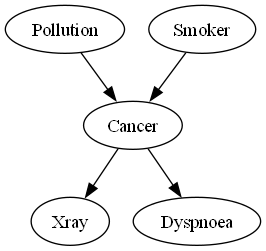

In [14]:
visualize_bn(cancer_model,'Cancer')

In [30]:
for cpd in cancer_model.get_cpds():
    print(cpd)

+---------------+----------------+----------------+-----------------+-----------------+
| Pollution     | Pollution(low) | Pollution(low) | Pollution(high) | Pollution(high) |
+---------------+----------------+----------------+-----------------+-----------------+
| Smoker        | Smoker(True)   | Smoker(False)  | Smoker(True)    | Smoker(False)   |
+---------------+----------------+----------------+-----------------+-----------------+
| Cancer(True)  | 0.03           | 0.001          | 0.05            | 0.02            |
+---------------+----------------+----------------+-----------------+-----------------+
| Cancer(False) | 0.97           | 0.999          | 0.95            | 0.98            |
+---------------+----------------+----------------+-----------------+-----------------+
+-----------------+--------------+---------------+
| Cancer          | Cancer(True) | Cancer(False) |
+-----------------+--------------+---------------+
| Dyspnoea(True)  | 0.65         | 0.3           |
+---

### Probability Query
Use the above CPD tables to compute the following probability.

To compute P(𝐶𝑎𝑛𝑐𝑒𝑟=𝑡𝑟𝑢𝑒| 𝑋𝑟𝑎𝑦 = positive, 𝐷𝑦𝑠𝑝𝑛𝑜𝑒𝑎=𝑇𝑟𝑢𝑒, 𝑃𝑜𝑙𝑙𝑢𝑡𝑖𝑜𝑛=ℎ𝑖𝑔ℎ, 𝑆𝑚𝑜𝑘𝑒𝑟=𝑇𝑟𝑢𝑒)
 
 What we did before...

In [15]:
# Get joint probability
cancerTrue = cancer_model.get_state_probability({'Pollution': 'high', 'Smoker': 'True', 'Cancer': 'True', 'Dyspnoea': 'True', 'Xray':'positive'})
cancerMarginal = cancer_model.get_state_probability({'Pollution': 'high', 'Smoker': 'True', 'Dyspnoea': 'True', 'Xray':'positive'})
cancerTrue / cancerMarginal

np.float64(0.3391304347826088)

#### Apply Variable Elimination to Compute Marginal Probabilities

In [16]:
cancer_inf = VariableElimination(cancer_model)

In [17]:
print(cancer_inf.query(['Cancer']))

+---------------+---------------+
| Cancer        |   phi(Cancer) |
+===============+===============+
| Cancer(True)  |        0.0116 |
+---------------+---------------+
| Cancer(False) |        0.9884 |
+---------------+---------------+


#### Apply Variable Elimination to Compute Joint Probabilities

In [18]:
print(cancer_inf.query(['Cancer', 'Dyspnoea']))

+---------------+-----------------+------------------------+
| Cancer        | Dyspnoea        |   phi(Cancer,Dyspnoea) |
+===============+=================+========================+
| Cancer(True)  | Dyspnoea(True)  |                 0.0076 |
+---------------+-----------------+------------------------+
| Cancer(True)  | Dyspnoea(False) |                 0.0041 |
+---------------+-----------------+------------------------+
| Cancer(False) | Dyspnoea(True)  |                 0.2965 |
+---------------+-----------------+------------------------+
| Cancer(False) | Dyspnoea(False) |                 0.6919 |
+---------------+-----------------+------------------------+


#### Apply Variable Elimination to Compute Conditional Probabilities

In [19]:
print(cancer_inf.query(['Cancer'], evidence={'Pollution': 'high', 'Smoker': 'True', 'Dyspnoea': 'True', 'Xray':'positive'}))

+---------------+---------------+
| Cancer        |   phi(Cancer) |
+===============+===============+
| Cancer(True)  |        0.3391 |
+---------------+---------------+
| Cancer(False) |        0.6609 |
+---------------+---------------+


### Activity I: Answer the following probability queries

How likely does a patient get both Cancer and Dyspnoea, if he is a smoker?

In [20]:
print(cancer_inf.query(['Cancer','Dyspnoea'], evidence={ 'Smoker': 'True'}))

+---------------+-----------------+------------------------+
| Cancer        | Dyspnoea        |   phi(Cancer,Dyspnoea) |
+===============+=================+========================+
| Cancer(True)  | Dyspnoea(True)  |                 0.0208 |
+---------------+-----------------+------------------------+
| Cancer(True)  | Dyspnoea(False) |                 0.0112 |
+---------------+-----------------+------------------------+
| Cancer(False) | Dyspnoea(True)  |                 0.2904 |
+---------------+-----------------+------------------------+
| Cancer(False) | Dyspnoea(False) |                 0.6776 |
+---------------+-----------------+------------------------+


### Activity II: Evidential reasoning
A) What is the most likely cause if a patient has both Cancer and Dyspnoea?

In [21]:
print(cancer_inf.query(['Smoker','Pollution'], evidence={'Dyspnoea': 'True', 'Cancer': 'True'}))

+---------------+-----------------+-------------------------+
| Smoker        | Pollution       |   phi(Smoker,Pollution) |
+===============+=================+=========================+
| Smoker(True)  | Pollution(low)  |                  0.6965 |
+---------------+-----------------+-------------------------+
| Smoker(True)  | Pollution(high) |                  0.1290 |
+---------------+-----------------+-------------------------+
| Smoker(False) | Pollution(low)  |                  0.0542 |
+---------------+-----------------+-------------------------+
| Smoker(False) | Pollution(high) |                  0.1204 |
+---------------+-----------------+-------------------------+


Or you may investigate the marginal probability of Smoker and Pollution respectively.

In [22]:
print(cancer_inf.query(['Smoker'], evidence={'Dyspnoea': 'True', 'Cancer': 'True'}))

+---------------+---------------+
| Smoker        |   phi(Smoker) |
+===============+===============+
| Smoker(True)  |        0.8255 |
+---------------+---------------+
| Smoker(False) |        0.1745 |
+---------------+---------------+


In [23]:
print(cancer_inf.query(['Pollution'], evidence={'Dyspnoea': 'True', 'Cancer': 'True'}))

+-----------------+------------------+
| Pollution       |   phi(Pollution) |
+=================+==================+
| Pollution(low)  |           0.7506 |
+-----------------+------------------+
| Pollution(high) |           0.2494 |
+-----------------+------------------+


B) **Explaining Away:** The patient has both Cancer and Dyspnoea. If we know that the patient lives in a highly polluted area, what conclusion will you draw?

In [24]:
print(cancer_inf.query(['Smoker'], evidence={'Dyspnoea': 'True', 'Cancer': 'True', 'Pollution': 'high'}))

+---------------+---------------+
| Smoker        |   phi(Smoker) |
+===============+===============+
| Smoker(True)  |        0.5172 |
+---------------+---------------+
| Smoker(False) |        0.4828 |
+---------------+---------------+


### Demo: We know that Xray and Smoker is d-separated by Cancer, show that $Xray \perp Smoker | Cancer$.

In [25]:
prob_smoker = cancer_inf.query(['Smoker'], evidence={'Cancer': 'True'})
print(prob_smoker)

+---------------+---------------+
| Smoker        |   phi(Smoker) |
+===============+===============+
| Smoker(True)  |        0.8255 |
+---------------+---------------+
| Smoker(False) |        0.1745 |
+---------------+---------------+


In [26]:
prob_xray = cancer_inf.query(['Xray'], evidence={'Cancer': 'True'})
print(prob_xray)

+----------------+-------------+
| Xray           |   phi(Xray) |
+================+=============+
| Xray(positive) |      0.9000 |
+----------------+-------------+
| Xray(negative) |      0.1000 |
+----------------+-------------+


In [27]:
prob_xray_smoker = cancer_inf.query(['Xray', 'Smoker'], evidence={'Cancer': 'True'})
print(prob_xray_smoker)

+----------------+---------------+--------------------+
| Xray           | Smoker        |   phi(Xray,Smoker) |
+================+===============+====================+
| Xray(positive) | Smoker(True)  |             0.7429 |
+----------------+---------------+--------------------+
| Xray(positive) | Smoker(False) |             0.1571 |
+----------------+---------------+--------------------+
| Xray(negative) | Smoker(True)  |             0.0825 |
+----------------+---------------+--------------------+
| Xray(negative) | Smoker(False) |             0.0175 |
+----------------+---------------+--------------------+


In [28]:
print(prob_xray * prob_smoker)

+----------------+---------------+--------------------+
| Xray           | Smoker        |   phi(Xray,Smoker) |
+================+===============+====================+
| Xray(positive) | Smoker(True)  |             0.7429 |
+----------------+---------------+--------------------+
| Xray(positive) | Smoker(False) |             0.1571 |
+----------------+---------------+--------------------+
| Xray(negative) | Smoker(True)  |             0.0825 |
+----------------+---------------+--------------------+
| Xray(negative) | Smoker(False) |             0.0175 |
+----------------+---------------+--------------------+


We show that $P(Xray, Smoker | Cancer = True) = P(Xray | Cancer = True)P(Smoker | Cancer=True)$

## 2. Elimination Order

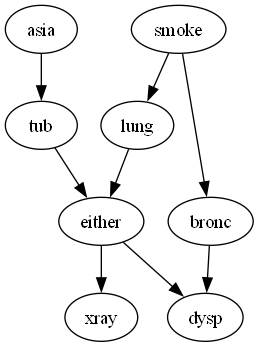

In [31]:
asia_model = load_model("bnlearn/asia")
visualize_bn(asia_model)

In [32]:
for cpd in asia_model.get_cpds():
    print(cpd)

+-----------+------+
| asia(yes) | 0.01 |
+-----------+------+
| asia(no)  | 0.99 |
+-----------+------+
+------------+------------+-----------+
| smoke      | smoke(yes) | smoke(no) |
+------------+------------+-----------+
| bronc(yes) | 0.6        | 0.3       |
+------------+------------+-----------+
| bronc(no)  | 0.4        | 0.7       |
+------------+------------+-----------+
+-----------+-------------+------------+-------------+------------+
| bronc     | bronc(yes)  | bronc(yes) | bronc(no)   | bronc(no)  |
+-----------+-------------+------------+-------------+------------+
| either    | either(yes) | either(no) | either(yes) | either(no) |
+-----------+-------------+------------+-------------+------------+
| dysp(yes) | 0.9         | 0.8        | 0.7         | 0.1        |
+-----------+-------------+------------+-------------+------------+
| dysp(no)  | 0.1         | 0.2        | 0.3         | 0.9        |
+-----------+-------------+------------+-------------+------------+
+--

In [33]:
inf_asia = VariableElimination(asia_model)

In [34]:
def evaluate_order(inference, order):
    start_time = time.time()
    result = inference.query(variables=['xray','dysp'], elimination_order=order, show_progress=False)
    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"Running time: {elapsed_time:.6f} seconds")
    print(result)

### Demo: Apply the above method to the Asia model with different elimination orders: greedy, MinFill, MinNeighbors, MinWeight, WeightedMinFill and compare their efficiency.

In [35]:
evaluate_order(inf_asia, 'greedy')

Running time: 0.077353 seconds
+-----------+-----------+------------------+
| xray      | dysp      |   phi(xray,dysp) |
+===========+===========+==================+
| xray(yes) | dysp(yes) |           0.0707 |
+-----------+-----------+------------------+
| xray(yes) | dysp(no)  |           0.0396 |
+-----------+-----------+------------------+
| xray(no)  | dysp(yes) |           0.3653 |
+-----------+-----------+------------------+
| xray(no)  | dysp(no)  |           0.5244 |
+-----------+-----------+------------------+


In [36]:
evaluate_order(inf_asia, 'MinFill')

Running time: 0.007007 seconds
+-----------+-----------+------------------+
| xray      | dysp      |   phi(xray,dysp) |
+===========+===========+==================+
| xray(yes) | dysp(yes) |           0.0707 |
+-----------+-----------+------------------+
| xray(yes) | dysp(no)  |           0.0396 |
+-----------+-----------+------------------+
| xray(no)  | dysp(yes) |           0.3653 |
+-----------+-----------+------------------+
| xray(no)  | dysp(no)  |           0.5244 |
+-----------+-----------+------------------+


In [37]:
evaluate_order(inf_asia, 'MinNeighbors')

Running time: 0.006015 seconds
+-----------+-----------+------------------+
| xray      | dysp      |   phi(xray,dysp) |
+===========+===========+==================+
| xray(yes) | dysp(yes) |           0.0707 |
+-----------+-----------+------------------+
| xray(yes) | dysp(no)  |           0.0396 |
+-----------+-----------+------------------+
| xray(no)  | dysp(yes) |           0.3653 |
+-----------+-----------+------------------+
| xray(no)  | dysp(no)  |           0.5244 |
+-----------+-----------+------------------+


In [38]:
evaluate_order(inf_asia, 'MinWeight')

Running time: 0.004005 seconds
+-----------+-----------+------------------+
| xray      | dysp      |   phi(xray,dysp) |
+===========+===========+==================+
| xray(yes) | dysp(yes) |           0.0707 |
+-----------+-----------+------------------+
| xray(yes) | dysp(no)  |           0.0396 |
+-----------+-----------+------------------+
| xray(no)  | dysp(yes) |           0.3653 |
+-----------+-----------+------------------+
| xray(no)  | dysp(no)  |           0.5244 |
+-----------+-----------+------------------+


In [39]:
evaluate_order(inf_asia, 'WeightedMinFill')

Running time: 0.006995 seconds
+-----------+-----------+------------------+
| xray      | dysp      |   phi(xray,dysp) |
+===========+===========+==================+
| xray(yes) | dysp(yes) |           0.0707 |
+-----------+-----------+------------------+
| xray(yes) | dysp(no)  |           0.0396 |
+-----------+-----------+------------------+
| xray(no)  | dysp(yes) |           0.3653 |
+-----------+-----------+------------------+
| xray(no)  | dysp(no)  |           0.5244 |
+-----------+-----------+------------------+


## 3. MAP Query

If a patient is a smoker and has visited Asia recently, what are the most probable diseases?

In [40]:
print(inf_asia.map_query(['lung','dysp','bronc','tub'], evidence={'asia': 'yes', 'smoke': 'yes'}))

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

{'lung': 'no', 'tub': 'no', 'dysp': 'yes', 'bronc': 'yes'}


## 4. Student Scenario

Four students who get together in pairs to work on the homework for a class. For various reasons, only the following pairs meet: Alice and Bob; Bob and Charles; Charles and Debbie; and Debbie and Alice. (Alice and Charles just can’t stand each other, and Bob and Debbie had a relationship that ended badly.)
The professor made a mistake in class. Any of the four students may figure out the problem and transmit this understanding to his or her study partners. We need to determine whether a student has the misconception or not.

In [42]:
mn_student = DiscreteMarkovNetwork()
mn_student.add_edges_from([('Alice', 'Bob'), ('Alice', 'Debbie'), ('Bob','Charles'), ('Debbie','Charles')])
factor_ab = DiscreteFactor(['Alice', 'Bob'], cardinality=[2, 2],
                values=np.random.rand(4))
factor_ad = DiscreteFactor(['Alice', 'Debbie'], cardinality=[2, 2],
                values=np.random.rand(4))
factor_bc = DiscreteFactor(['Bob', 'Charles'],  cardinality=[2, 2], values=np.random.rand(4))
factor_dc = DiscreteFactor(['Debbie', 'Charles'],  cardinality=[2, 2], values=np.random.rand(4))
mn_student.add_factors(factor_ab, factor_ad, factor_bc, factor_dc)

In [43]:
for factor in mn_student.get_factors():
    print(factor)

+----------+--------+------------------+
| Alice    | Bob    |   phi(Alice,Bob) |
+==========+========+==================+
| Alice(0) | Bob(0) |           0.3819 |
+----------+--------+------------------+
| Alice(0) | Bob(1) |           0.1307 |
+----------+--------+------------------+
| Alice(1) | Bob(0) |           0.3223 |
+----------+--------+------------------+
| Alice(1) | Bob(1) |           0.4715 |
+----------+--------+------------------+
+----------+-----------+---------------------+
| Alice    | Debbie    |   phi(Alice,Debbie) |
+==========+===========+=====================+
| Alice(0) | Debbie(0) |              0.3499 |
+----------+-----------+---------------------+
| Alice(0) | Debbie(1) |              0.8125 |
+----------+-----------+---------------------+
| Alice(1) | Debbie(0) |              0.7595 |
+----------+-----------+---------------------+
| Alice(1) | Debbie(1) |              0.3754 |
+----------+-----------+---------------------+
+--------+------------+---------

In [44]:
def visualize_mn(markov_net, title="Markov Network"):
    # Use a specific layout (you can try different layouts if spring_layout causes issues)
    pos = nx.shell_layout(markov_net)  # Alternative layout

    # Visualize the graph
    plt.figure(figsize=(8, 6))  # Set the size of the plot
    nx.draw(markov_net, pos, with_labels=True, node_size=5000, node_color="skyblue", font_size=12, font_weight="bold", edge_color="black")
    # add title
    plt.title(title, fontsize=15, fontweight="bold")
    # Display the graph
    plt.show()

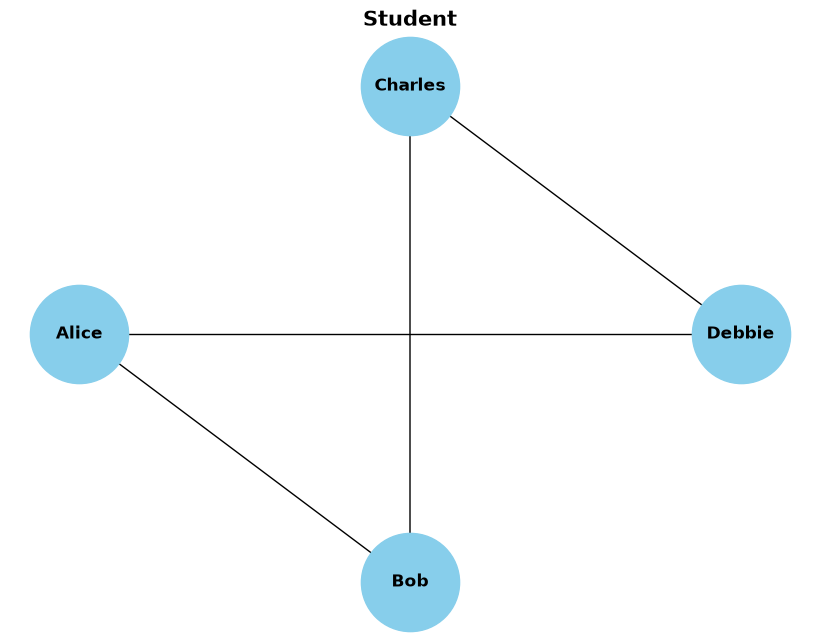

In [45]:
visualize_mn(mn_student, 'Student')

### Demo: Inference with the student  example

Compute $P(Bob)$ with variable elimination.

In [46]:
var_inf = VariableElimination(mn_student)
print(var_inf.query(['Bob']))

+--------+------------+
| Bob    |   phi(Bob) |
+========+============+
| Bob(0) |     0.4403 |
+--------+------------+
| Bob(1) |     0.2500 |
+--------+------------+


Answer the same query with [belief propagation in junction tree](https://ermongroup.github.io/cs228-notes/inference/jt/), however, understanding of this algorithm is optional.

In [47]:
belief_inf = BeliefPropagation(mn_student)
print(belief_inf.query(['Bob']))

+--------+------------+
| Bob    |   phi(Bob) |
+========+============+
| Bob(0) |     0.6379 |
+--------+------------+
| Bob(1) |     0.3621 |
+--------+------------+


Variable elimination is not applicable to the above Markov network because its graphicl structure contains cycles.